<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 24: Graphical Model Sampling and Probabilistic Inference

**Category**: CO4 – Linear Factor Models and Probabilistic Graphical Models  
**Objective**: Perform ancestral rejection sampling on graphical networks and evaluate posterior marginal inferences under evidence observations.


### Task 1: Implement Forward Ancestral Sampling on Bayesian Network


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
n_samples = 80000

# 1. Sample Difficulty (0: Easy, 1: Hard) -> P(Hard) = 0.40
D = (np.random.rand(n_samples) < 0.40).astype(int)

# 2. Sample Intelligence (0: Low, 1: High) -> P(High) = 0.30
I = (np.random.rand(n_samples) < 0.30).astype(int)

# 3. Sample Grade (0: C, 1: B, 2: A) based on (D, I)
# Probability table for Grade=A:
p_A = np.where((D == 0) & (I == 1), 0.85,
      np.where((D == 0) & (I == 0), 0.35,
      np.where((D == 1) & (I == 1), 0.50, 0.05)))
G = (np.random.rand(n_samples) < p_A).astype(int) # 1: Grade A, 0: Other

# 4. Sample SAT (1: High, 0: Low) based on Intelligence
p_SAT = np.where(I == 1, 0.85, 0.15)
S = (np.random.rand(n_samples) < p_SAT).astype(int)

print(f"Generated {n_samples:,} Ancestral Samples from Joint Distribution P(D, I, G, S).")


Generated 80,000 Ancestral Samples from Joint Distribution P(D, I, G, S).


### Task 2: Compute Posterior Inferences: P(Intelligence=High | Evidence)


In [2]:
# Inference 1: Prior P(I = High)
prior_I = np.mean(I == 1)
print(f"1. Prior P(Intelligence = High): {prior_I * 100:.2f}%")

# Inference 2: Posterior P(I = High | Grade = A)
ev_grade_A = (G == 1)
post_I_given_G = np.mean(I[ev_grade_A] == 1)
print(f"2. Posterior P(Intelligence = High | Grade = A): {post_I_given_G * 100:.2f}%")

# Inference 3: Posterior P(I = High | Grade = A, Difficulty = Hard) (Explaining Away)
ev_hard_A = (G == 1) & (D == 1)
post_I_given_hard_A = np.mean(I[ev_hard_A] == 1)
print(f"3. Posterior P(Intelligence = High | Grade = A, Difficulty = Hard): {post_I_given_hard_A * 100:.2f}%")


1. Prior P(Intelligence = High): 29.97%
2. Posterior P(Intelligence = High | Grade = A): 56.65%
3. Posterior P(Intelligence = High | Grade = A, Difficulty = Hard): 81.11%


### Task 3: Visualize Posterior Probability Shifts Across Evidence Conditions


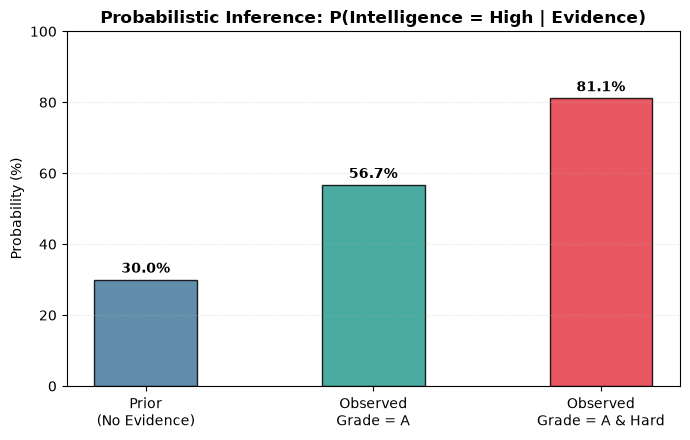

In [3]:
conditions = ['Prior\n(No Evidence)', 'Observed\nGrade = A', 'Observed\nGrade = A & Hard']
probs = [prior_I * 100, post_I_given_G * 100, post_I_given_hard_A * 100]

plt.figure(figsize=(7, 4.5))
bars = plt.bar(conditions, probs, color=['#457b9d', '#2a9d8f', '#e63946'], edgecolor='k', alpha=0.85, width=0.45)
plt.title("Probabilistic Inference: P(Intelligence = High | Evidence)", fontweight='bold')
plt.ylabel("Probability (%)")
plt.ylim(0, 100)

for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 2, f"{h:.1f}%", ha='center', fontweight='bold')

plt.grid(True, linestyle=':', alpha=0.4, axis='y')
plt.tight_layout()
plt.show()
